In [6]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
ds = xr.open_dataset("../global-marine-litter-2020.nc")

print(ds)

<xarray.Dataset> Size: 2GB
Dimensions:  (traj: 387600, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB ...
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 1GB ...
    lat      (traj, obs) float32 1GB ...
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


In [10]:
print("First observation:", ds.time.values[0])
print("Last observation:", ds.time.values[-1])
print("Number of observations:", len(ds.time))

First observation: 2020-01-01T00:00:00.000000000
Last observation: 2022-01-02T00:00:00.000000000
Number of observations: 733


In [12]:
time_difference = ds.time.values[1] - ds.time.values[0]

print("Time interval:", time_difference / np.timedelta64(1, 'h'), "hours")

Time interval: 24.0 hours


In [14]:
start_lat = ds.lat.isel(obs=0)
start_lon = ds.lon.isel(obs=0)

print("Starting latitude range:", 
      float(start_lat.min()), float(start_lat.max()))

print("Starting longitude range:", 
      float(start_lon.min()), float(start_lon.max()))

Starting latitude range: -55.36840057373047 69.87090301513672
Starting longitude range: -175.53689575195312 179.35499572753906


In [15]:
atlantic_mask = (
    (start_lat >= -60) &
    (start_lat <= 70) &
    (start_lon >= -100) &
    (start_lon <= 20)
)

print("Total particles:", ds.sizes["traj"])
print("Particles starting in Atlantic:", int(atlantic_mask.sum()))

Total particles: 387600
Particles starting in Atlantic: 9306


In [16]:
atlantic_ds = ds.isel(traj=atlantic_mask)

print(atlantic_ds)

<xarray.Dataset> Size: 55MB
Dimensions:  (traj: 9306, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB 2020-01-01 2020-01-02 ... 2022-01-02
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 27MB ...
    lat      (traj, obs) float32 27MB ...
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


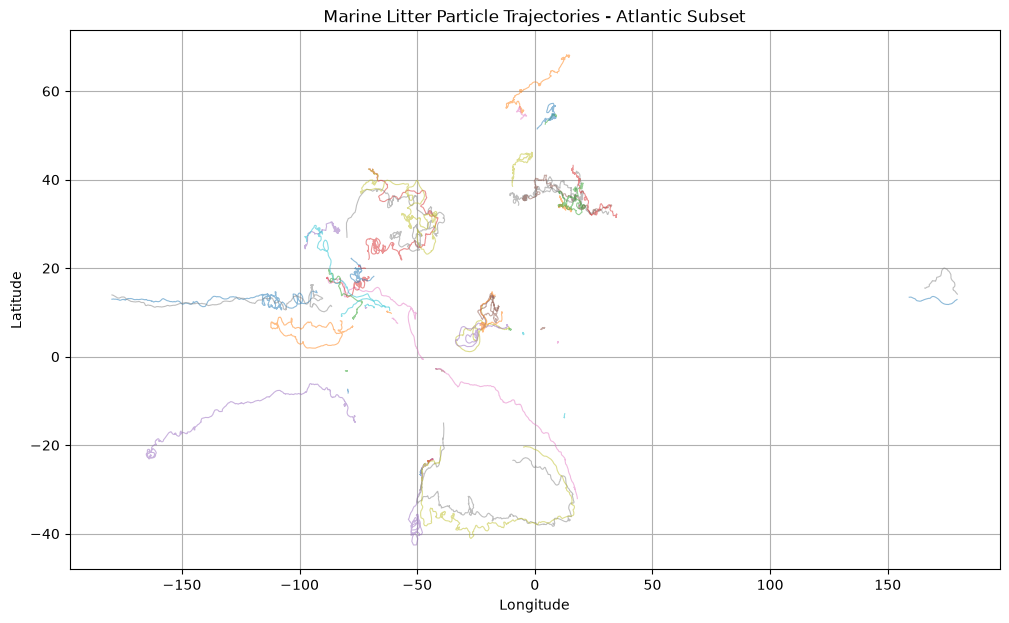

In [18]:
plt.figure(figsize=(12, 7))

for i in range(50):
    lon = sample.lon.values[i, :].copy()
    lat = sample.lat.values[i, :].copy()

    # Break lines when particles cross the International Date Line
    jumps = np.where(np.abs(np.diff(lon)) > 180)[0] + 1

    lon[jumps] = np.nan
    lat[jumps] = np.nan

    plt.plot(lon, lat, alpha=0.5, linewidth=0.8)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Marine Litter Particle Trajectories - Atlantic Subset")
plt.grid()
plt.show()

In [23]:
# Get all particle coordinates
lat = ds.lat.values
lon = ds.lon.values

# Identify valid positions
valid = np.isfinite(lat) & np.isfinite(lon)

# Find the first valid observation for each particle
first_indices = valid.argmax(axis=1)

particle_indices = np.arange(ds.sizes["traj"])

# Extract each particle's starting coordinates
start_lat_all = lat[particle_indices, first_indices]
start_lon_all = lon[particle_indices, first_indices]

# Exclude particles without valid positions
has_data = valid.any(axis=1)

# Identify particles starting in the Atlantic
atlantic_mask_all = (
    has_data &
    (start_lat_all >= -60) &
    (start_lat_all <= 70) &
    (start_lon_all >= -100) &
    (start_lon_all <= 20)
)

print("Total particles:", ds.sizes["traj"])
print("Particles starting in Atlantic:", int(atlantic_mask_all.sum()))

Total particles: 387600
Particles starting in Atlantic: 111672


In [24]:
atlantic_ds = ds.isel(traj=atlantic_mask_all)

print(atlantic_ds)

<xarray.Dataset> Size: 655MB
Dimensions:  (traj: 111672, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB 2020-01-01 2020-01-02 ... 2022-01-02
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 327MB -99.5 -99.24 -98.98 ... -49.7 -49.71
    lat      (traj, obs) float32 327MB 16.48 16.49 16.42 ... 0.02313 0.02841
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


In [25]:
# Extract particle coordinates
lat = atlantic_ds.lat.values
lon = atlantic_ds.lon.values

# Identify valid observations
valid = np.isfinite(lat) & np.isfinite(lon)

# Find each particle's first valid observation
first_indices = valid.argmax(axis=1)

particle_indices = np.arange(len(first_indices))

# Get each particle's starting coordinates
start_lat = lat[particle_indices, first_indices]
start_lon = lon[particle_indices, first_indices]

# Calculate distance from each particle's own starting position
lat1 = np.radians(start_lat[:, None])
lat2 = np.radians(lat)

dlat = lat2 - lat1
dlon = np.radians(lon - start_lon[:, None])

a = (np.sin(dlat / 2)**2 +
     np.cos(lat1) * np.cos(lat2) *
     np.sin(dlon / 2)**2)

displacement = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

# Exclude observations before particle release
displacement[~valid] = np.nan

print("Number of particles:", len(displacement))
print("Displacement array shape:", displacement.shape)
print("Valid starting positions:", valid.any(axis=1).sum())

Number of particles: 111672
Displacement array shape: (111672, 733)
Valid starting positions: 111672


In [37]:
# Correct longitude differences across the International Date Line
dlon = np.radians(
    (lon - start_lon[:, None] + 180) % 360 - 180
)

dlat = np.radians(lat) - np.radians(start_lat[:, None])

a = (np.sin(dlat / 2)**2 +
     np.cos(np.radians(start_lat[:, None])) *
     np.cos(np.radians(lat)) *
     np.sin(dlon / 2)**2)

displacement = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

displacement[~valid] = np.nan

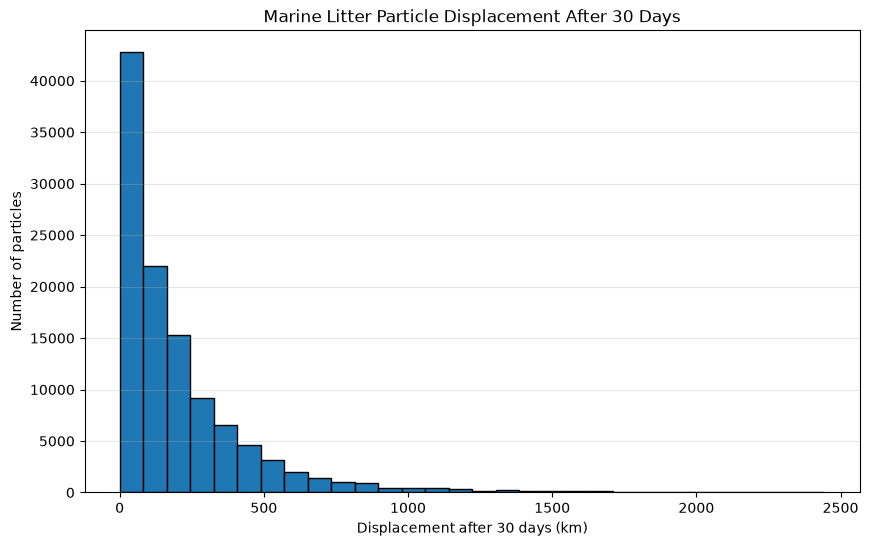

In [27]:
# Select displacement 30 days after each particle's release
target_indices = first_indices + 30

# Keep particles with a valid observation 30 days later
available = target_indices < ds.sizes["obs"]

particle_ids = np.arange(len(first_indices))[available]
target_days = target_indices[available]

valid_30 = valid[particle_ids, target_days]

distance_30 = displacement[particle_ids[valid_30],
                            target_days[valid_30]]

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(distance_30, bins=30, edgecolor="black")

plt.xlabel("Displacement after 30 days (km)")
plt.ylabel("Number of particles")
plt.title("Marine Litter Particle Displacement After 30 Days")

plt.grid(axis="y", alpha=0.3)
plt.show()

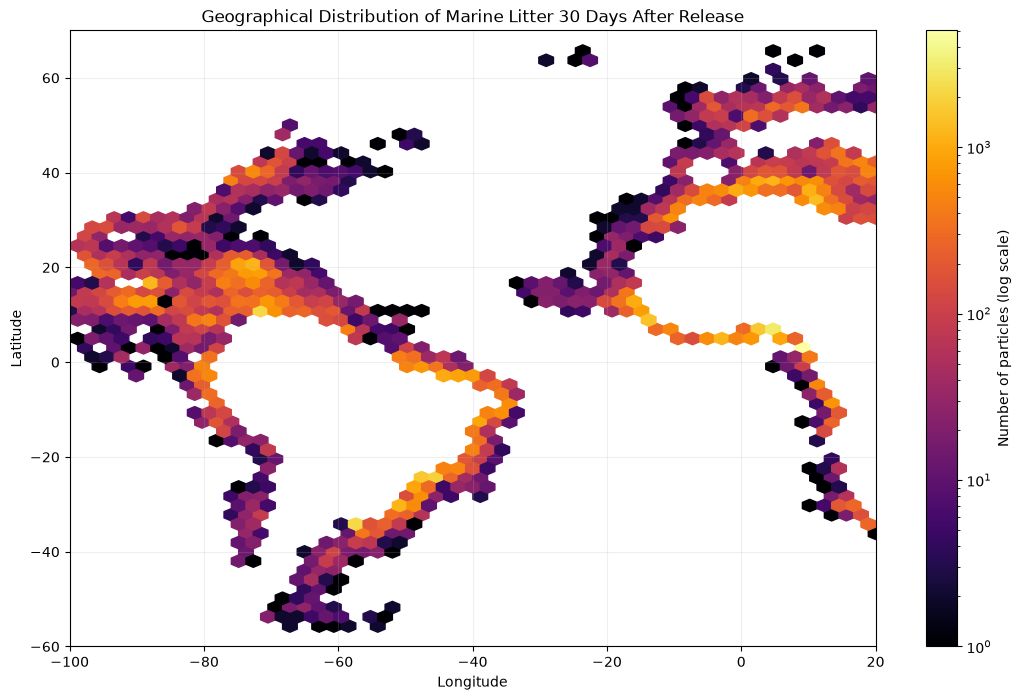

In [29]:
# Get particle positions 30 days after release
lon_30 = lon[particle_ids, target_days]
lat_30 = lat[particle_ids, target_days]

# Keep positions within our Atlantic study region
atlantic_region = (
    (lon_30 >= -100) & (lon_30 <= 20) &
    (lat_30 >= -60) & (lat_30 <= 70)
)

lon_plot = lon_30[atlantic_region]
lat_plot = lat_30[atlantic_region]

# Create density map
plt.figure(figsize=(13, 8))

plt.hexbin(
    lon_plot,
    lat_plot,
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="inferno"
)

plt.colorbar(label="Number of particles (log scale)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Geographical Distribution of Marine Litter "
    "30 Days After Release"
)

plt.xlim(-100, 20)
plt.ylim(-60, 70)
plt.grid(alpha=0.2)

plt.show()

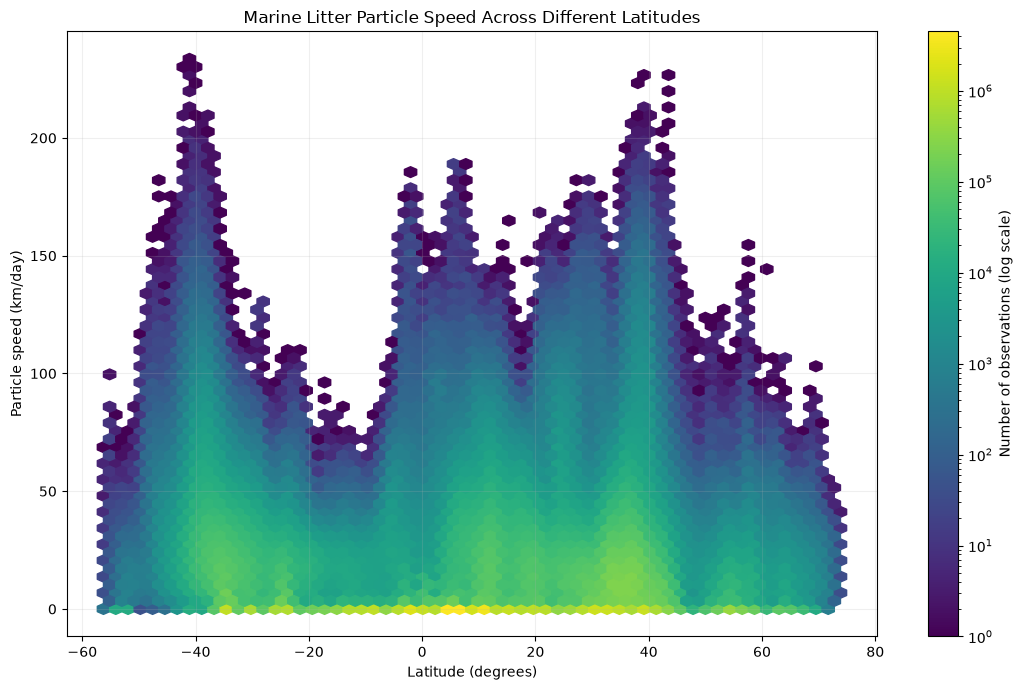

In [30]:
# Coordinates on consecutive days
lat1 = np.radians(lat[:, :-1])
lat2 = np.radians(lat[:, 1:])

lon1 = np.radians(lon[:, :-1])
lon2 = np.radians(lon[:, 1:])

# Calculate daily coordinate differences
dlat = lat2 - lat1
dlon = (lon2 - lon1 + np.pi) % (2 * np.pi) - np.pi

# Haversine distance between consecutive positions
a = (np.sin(dlat / 2)**2 +
     np.cos(lat1) * np.cos(lat2) *
     np.sin(dlon / 2)**2)

daily_distance = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

# Only use consecutive valid positions
valid_pairs = valid[:, :-1] & valid[:, 1:]

daily_speed = daily_distance[valid_pairs]

# Latitude halfway between consecutive observations
mid_lat = (lat[:, :-1] + lat[:, 1:]) / 2
speed_lat = mid_lat[valid_pairs]

# Remove invalid values
keep = np.isfinite(daily_speed) & np.isfinite(speed_lat)

daily_speed = daily_speed[keep]
speed_lat = speed_lat[keep]

# Plot speed against latitude
plt.figure(figsize=(11, 7))

plt.hexbin(
    speed_lat,
    daily_speed,
    gridsize=60,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="Number of observations (log scale)")
plt.xlabel("Latitude (degrees)")
plt.ylabel("Particle speed (km/day)")
plt.title("Marine Litter Particle Speed Across Different Latitudes")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

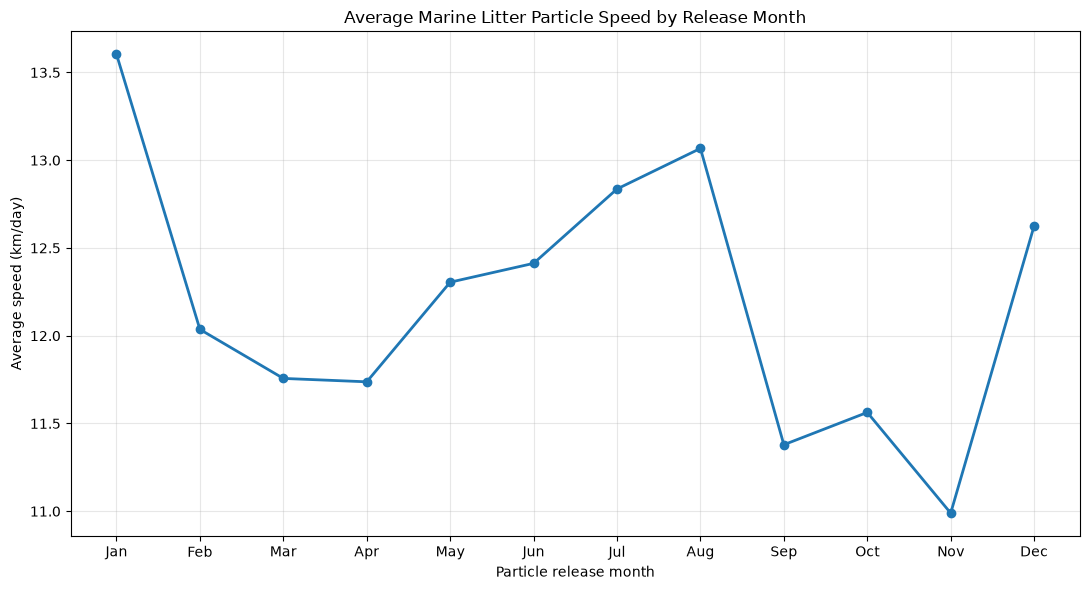

In [31]:
# Calculate average speed during the first 30 days
monthly_speeds = {}
release_months = []

for i in range(len(first_indices)):

    start = first_indices[i]

    if start + 30 < ds.sizes["obs"]:

        speeds = daily_distance[i, start:start + 30]
        pair_valid = valid_pairs[i, start:start + 30]

        usable_speeds = speeds[pair_valid]

        if len(usable_speeds) >= 25:
            monthly_speeds.setdefault(
                int(pd.Timestamp(ds.time.values[start]).month), []
            ).append(np.mean(usable_speeds))

# Calculate monthly averages
months = list(range(1, 13))

average_speeds = [
    np.mean(monthly_speeds[m]) if m in monthly_speeds else np.nan
    for m in months
]

# Plot
plt.figure(figsize=(11, 6))

plt.plot(
    months,
    average_speeds,
    marker="o",
    linewidth=2
)

plt.xticks(months, [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.xlabel("Particle release month")
plt.ylabel("Average speed (km/day)")
plt.title("Average Marine Litter Particle Speed by Release Month")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

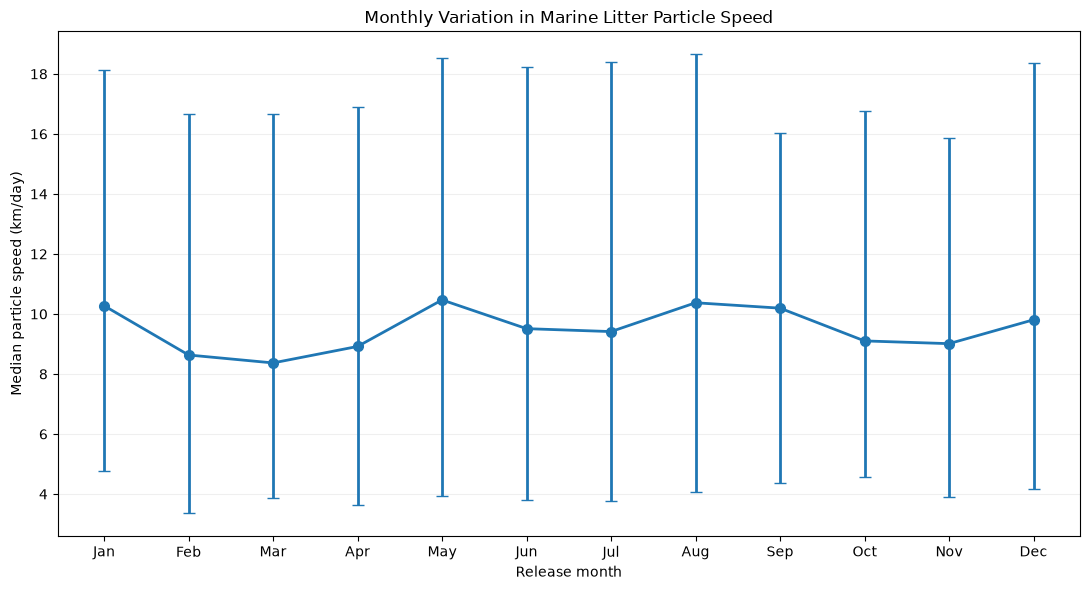

In [34]:
monthly_medians = [
    np.median(monthly_speeds[m]) for m in range(1, 13)
]

monthly_q1 = [
    np.percentile(monthly_speeds[m], 25) for m in range(1, 13)
]

monthly_q3 = [
    np.percentile(monthly_speeds[m], 75) for m in range(1, 13)
]

lower_error = np.array(monthly_medians) - np.array(monthly_q1)
upper_error = np.array(monthly_q3) - np.array(monthly_medians)

plt.figure(figsize=(11, 6))

plt.errorbar(
    range(1, 13),
    monthly_medians,
    yerr=[lower_error, upper_error],
    fmt='o-',
    markersize=7,
    linewidth=2,
    capsize=4
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.xlabel("Release month")
plt.ylabel("Median particle speed (km/day)")
plt.title("Monthly Variation in Marine Litter Particle Speed")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

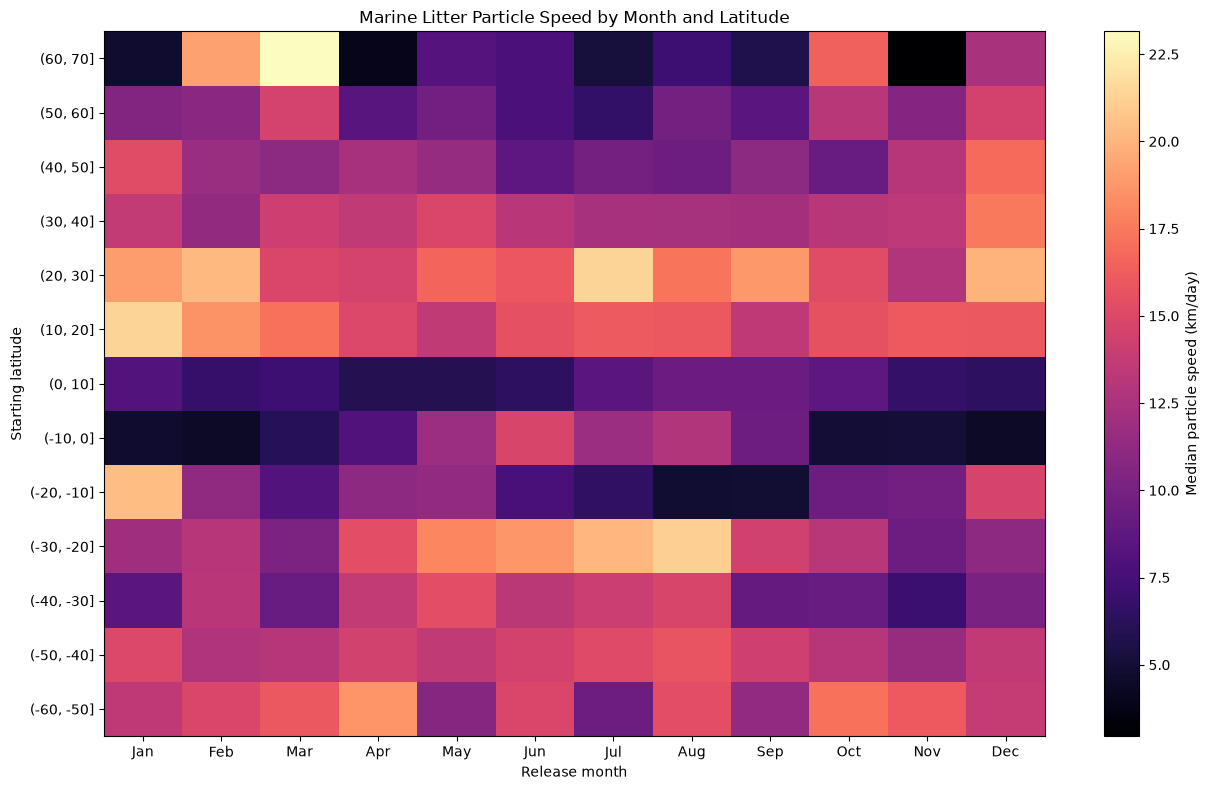

In [35]:
# Calculate average speed during each particle's first 30 days
records = []

for i in range(len(first_indices)):

    start = first_indices[i]
    end = start + 30

    if end < ds.sizes["obs"]:

        speeds = daily_distance[i, start:end]
        pair_valid = valid_pairs[i, start:end]

        usable = speeds[pair_valid]

        if len(usable) >= 25:

            records.append({
                "Month": pd.Timestamp(
                    ds.time.values[start]
                ).month,
                "Latitude": start_lat[i],
                "Speed": np.mean(usable)
            })

# Convert results into a DataFrame
speed_df = pd.DataFrame(records)

# Group latitude into 10-degree bands
speed_df["Latitude band"] = pd.cut(
    speed_df["Latitude"],
    bins=np.arange(-60, 81, 10)
)

# Calculate median speed for each month and latitude band
heatmap_data = speed_df.pivot_table(
    index="Latitude band",
    columns="Month",
    values="Speed",
    observed=False
)

# Plot heatmap
plt.figure(figsize=(13, 8))

plt.imshow(
    heatmap_data,
    aspect="auto",
    origin="lower",
    cmap="magma",
    interpolation="nearest"
)

plt.colorbar(label="Median particle speed (km/day)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index.astype(str)
)

plt.xlabel("Release month")
plt.ylabel("Starting latitude")
plt.title("Marine Litter Particle Speed by Month and Latitude")

plt.tight_layout()
plt.show()

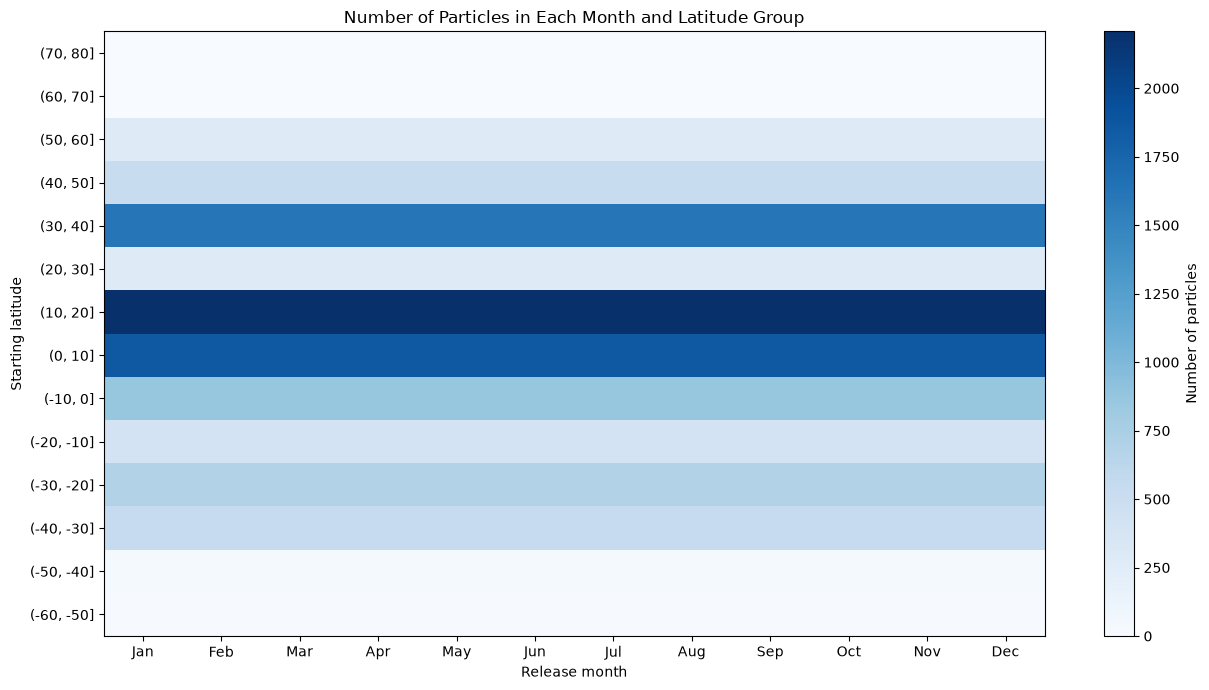

In [36]:
# Count particles in each month and latitude band
count_data = speed_df.pivot_table(
    index="Latitude band",
    columns="Month",
    values="Speed",
    aggfunc="count",
    observed=False
)

plt.figure(figsize=(13, 7))

plt.imshow(
    count_data,
    aspect="auto",
    origin="lower",
    cmap="Blues"
)

plt.colorbar(label="Number of particles")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(count_data.index)),
    count_data.index.astype(str)
)

plt.xlabel("Release month")
plt.ylabel("Starting latitude")
plt.title("Number of Particles in Each Month and Latitude Group")

plt.tight_layout()
plt.show()